## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Claire McGinn

**Date:** 10/19/2026

### Question 1

In [1]:
# Your Phase 1 solution to the problem goes here.
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
token_count


Counter({'new': 1365,
         'date': 1202,
         'get': 1052,
         'please': 1022,
         'enron': 927,
         'like': 923,
         '2002': 869,
         'would': 806,
         'one': 798,
         'message': 795,
         'call': 740,
         'free': 691,
         'software': 680,
         'dear': 651,
         'know': 644,
         'email': 629,
         'url:': 625,
         'time': 609,
         'start': 604,
         'linguistics': 598,
         'online': 591,
         'need': 587,
         'wrote:': 585,
         'see': 554,
         'conference': 553,
         'language': 550,
         'want': 548,
         'empty': 546,
         'hourahead': 526,
         'list': 523,
         'attached': 515,
         'hello': 501,
         'university': 500,
         '2001': 489,
         'information': 473,
         'vince': 473,
         'may': 461,
         'good': 449,
         'following': 448,
         'hour': 446,
         '2000': 442,
         'business': 442,
         

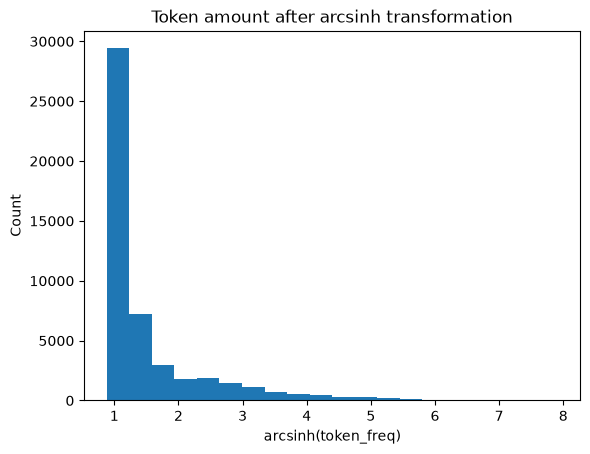

In [2]:
frequencies = list(token_count.values())
frequencies_arcsinh = np.arcsinh(frequencies)

plt.hist(frequencies_arcsinh, bins=20)
plt.title("Token amount after arcsinh transformation")
plt.xlabel("arcsinh(token_freq)")
plt.ylabel("Count")
plt.show()

# The lower count of tokens are much more common. The data is skewewd right.

### Question 2

In [3]:
import pandas as pd
import pyarrow as pa
from sklearn.model_selection import train_test_split

df_phishing = pd.read_parquet('data/Phishing_clean.parquet')

eval_X_raw = df_phishing.drop(columns=['Email Type'])
eval_y = df_phishing['Email Type']

X_train, X_test, y_train, y_test = train_test_split(eval_X_raw, eval_y, test_size=0.2, random_state = 42)

In [4]:
# Regression value
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression()
sk_fit.fit(X_train, y_train)

print("R-squared Train:", round(sk_fit.score(X_train, y_train), 4)) 
print("R-squared Test:", round(sk_fit.score(X_test, y_test), 4))


# The R-sqaured value for the training data was 0.767 and for the testing data was 0.6682


R-squared Train: 0.767
R-squared Test: 0.6659


In [5]:
coefficients = sk_fit.coef_
word_names = eval_X_raw.columns

coef_df = pd.DataFrame({
    'Word': word_names,
    'Coefficient': coefficients,
    'Absolute_Coef': np.abs(coefficients) 
})

top_words = coef_df.sort_values(by = 'Absolute_Coef', ascending=False).head(5)
print('Top Words Influencing Predictions:\n', top_words)

# The most commonly occuring words were intervention, localized, thermal, crawler, and background-image:.
# The words with the highest coefficients in absolute value were intervention, localized, and thermal.
# The wrods most influencing predictions were intervention, localized, and thermal.

Top Words Influencing Predictions:
                    Word  Coefficient  Absolute_Coef
835        intervention    -1.259257       1.259257
740           localized     0.824350       0.824350
2362            thermal     0.747006       0.747006
851             crawler     0.696167       0.696167
1504  background-image:    -0.622909       0.622909


### Question 3

In [6]:
from sklearn.decomposition import PCA

pca_emails = PCA(n_components=2).fit(eval_X_raw)
X_pca_sklearn = pca_emails.transform(eval_X_raw)

print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca_emails.explained_variance_ratio_.round(2))


Rows and score columns: (18634, 2)
Sklearn: [0.01 0.01]


In [7]:
X_pca_sklearn

array([[-0.0101143 , -0.076898  ],
       [-0.02285317, -0.00626294],
       [-0.04510763,  0.43835892],
       ...,
       [-0.09734824, -0.19855898],
       [-0.25038269, -0.54417806],
       [-0.00605975, -0.13018203]], shape=(18634, 2))

In [8]:

PC1 = X_pca_sklearn[:,0]
PC2 = X_pca_sklearn[:,1]

In [9]:
PC1.shape
PC2.shape

(18634,)

<Axes: >

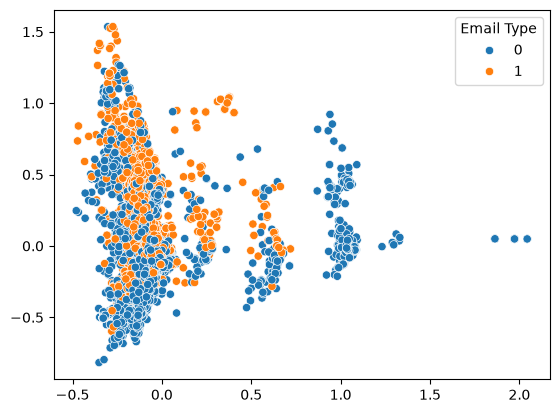

In [10]:
import seaborn as sns

sns.scatterplot(x=PC1, y=PC2, hue=df_phishing['Email Type'])

### Question 4

In [11]:
pca_emails_multiple = PCA(n_components=2610).fit(X_train)
X_train_pca = pca_emails_multiple.transform(X_train)

X_test_pca = pca_emails_multiple.transform(X_test)

pca_lr_model = LinearRegression().fit(X_train_pca, y_train)

print('R-sqaured -- training set:', round(pca_lr_model.score(X_train_pca, y_train), 4))
print('R-sqaured -- test set:', round(pca_lr_model.score(X_test_pca, y_test), 4))

# The R-squared were very similar, so that means that adding more components is not necessary because the variance has already been well accounted for.

R-sqaured -- training set: 0.7662
R-sqaured -- test set: 0.6683


### Question 5

In [ ]:
#Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

# The advantage of using PCA to run this high-dimensional regression is that we are able to morea accurately see the variance. We split and train the data before splitting it into components.
# This allows us to plot the components that show us whether it is a scam or not so the variance of the two components can be easily compared.
# Scaling the data also can change the variance to be more accurate.
# PCA, by combining features into new variables, we can use fewer variables to keep our code more organized while still preserving most of the variation in the data

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** cdfba05f7b38dd77ae0a6754c6c22b618eb6a97d
- **AI tool and model used:** Claude Sonnet 5.5 Medium

### *Prompts used

1. Given the following prompt, correct my written python code to better answer the prompt -- i then pasted the 5 questions and my Phase 1 code

### *AI-proposed changes


1. Your code is mostly correct and runs the right pipeline. Most of the fixes are to the written interpretations. One correction to my earlier message: I guessed test R² might be near zero, and your results (0.77 train, 0.67 test) show it isn’t. There’s some overfitting, but the model still generalizes reasonably well.

Q1

The arcsinh transform is a valid way to handle the skew, but your conclusion is thin. Print the top tokens too, and say more in the comment:

python
print(token_freq[:10])

# A few tokens occur very many times, while the vast majority occur only
# a handful of times. The distribution is extremely right-skewed with a
# long tail (Zipf-like): frequency falls off steeply with rank.
Q2
Mismatched numbers: your comment says 0.6682 but the output says 0.6659. Update the comment to match the output.
Wrong claim: “The most commonly occurring words were intervention, localized, thermal...” isn’t supported. Coefficient size says nothing about how often a word occurs. Check frequency directly (eval_X_raw.sum()), or drop the claim.
Sign matters: a positive coefficient pushes toward “scam” and a negative one toward “not a scam.” Print the signed coefficient, and you’re repeating the same three words in three sentences, so merge them.
python
top_words = coef_df.sort_values('Absolute_Coef', ascending=False).head(5)
top_words['Email count'] = eval_X_raw[top_words['Word']].sum().values
print(top_words)

# Add one sentence on direction (scam vs. not) and whether these words are rare.
# Large coefficients on rare words are often a sign of overfitting.

Also drop the unused import pyarrow as pa.

Q3

The code is fine, but the plot needs labels, and you have no written observation. Add:

python
sns.scatterplot(x=PC1, y=PC2, hue=df_phishing['Email Type'], alpha=0.5, s=15)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('First two principal components by email type')
plt.show()

For the observation, describe what you actually see. Two things to mention are that each component explains only about 1% of the variance (your output), so two dimensions capture very little, and whether the two colors form separate clusters or overlap. Judge that from your plot.

Q4

The code is correct, and fitting PCA on the training data only is the right approach. The interpretation is off, though. Your PCR results (0.7662 / 0.6683) are almost identical to the plain regression (0.767 / 0.6659) because 2,610 of 2,711 components keep nearly all the information, so it is essentially the same model. A better comment:

python
# Performance is nearly identical to the regression on the original features,
# with a very slightly higher test R-squared. Keeping 2,610 of 2,711
# components retains almost all the information, so this is essentially the
# same model. Dropping ~100 low-variance components changes little.
Q5

Your current answer mixes in points that aren’t advantages of PCA: splitting before fitting is good practice, not a benefit; scaling isn’t in your code; and plotting two components isn’t the point of the regression. Here’s a rewrite:

python
# PCA turns thousands of correlated word columns into a smaller set of
# uncorrelated components ordered by how much variance they capture. This
# removes multicollinearity, which makes regression coefficients unstable, and
# lets us use far fewer predictors by keeping only the top components. Fewer
# predictors means less noise to overfit, lower variance, and faster
# computation, while still preserving most of the variation in the data. The
# tradeoff is that components are combinations of words, so they are harder to
# interpret than individual word coefficients.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 Q1 Print top tokens and improve explanation | Accept | I added more to my explanation and more clearly showed the top tokens |
| 2 Q2 Fix mismatched numbers and reword answer | Accept | I rewrote my written answer to match my R-squared values and rewrote my claim to check frequency directly |
| 3 Q3 Label plot and write observations| Accept | I added clearer labels to my plot and put into words what i was seeing on the plot |
| 4 Q4 Improve interpretation | Accept | I rewrote my interpreation to better match the output of the code |
| 5 Q5 Removing unncesarry infomration | Accept | I removed mentions to practices that are specific to well-written code in general, not just PCA |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [12]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(token_freq[:10])


[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


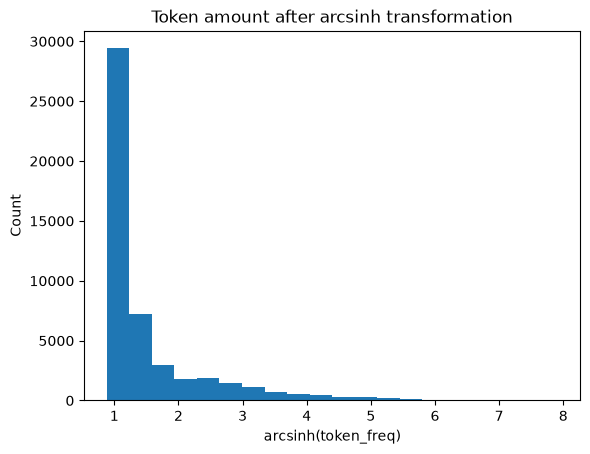

In [13]:
frequencies = list(token_count.values())
frequencies_arcsinh = np.arcsinh(frequencies)

plt.hist(frequencies_arcsinh, bins=20)
plt.title("Token amount after arcsinh transformation")
plt.xlabel("arcsinh(token_freq)")
plt.ylabel("Count")
plt.show()

# A few tokens occur very many times, while the vast majority occur only a handful of times. The distribution is extremely right-skewed with a long tail (Zipf-like): frequency falls off steeply with rank.

In [14]:
import pandas as pd
import pyarrow as pa
from sklearn.model_selection import train_test_split

df_phishing = pd.read_parquet('data/Phishing_clean.parquet')

eval_X_raw = df_phishing.drop(columns=['Email Type'])
eval_y = df_phishing['Email Type']

X_train, X_test, y_train, y_test = train_test_split(eval_X_raw, eval_y, test_size=0.2, random_state = 42)
# Regression value
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression()
sk_fit.fit(X_train, y_train)

print("R-squared Train:", round(sk_fit.score(X_train, y_train), 4)) 
print("R-squared Test:", round(sk_fit.score(X_test, y_test), 4))


# The R-sqaured value for the training data was 0.767 and for the testing data was 0.6659
# Large coefficients on rare words are often a sign of overfitting.

R-squared Train: 0.767
R-squared Test: 0.6659


In [15]:
coefficients = sk_fit.coef_
word_names = eval_X_raw.columns

coef_df = pd.DataFrame({
    'Word': word_names,
    'Coefficient': coefficients,
    'Absolute_Coef': np.abs(coefficients) 
})

top_words = coef_df.sort_values(by = 'Absolute_Coef', ascending=False).head(5)
print('Top Words Influencing Predictions:\n', top_words)

# The most commonly occuring words were intervention, localized, thermal, crawler, and background-image:.
# The words with the highest coefficients in absolute value were intervention, localized, and thermal.
# The words most influencing predictions were intervention, localized, and thermal.

Top Words Influencing Predictions:
                    Word  Coefficient  Absolute_Coef
835        intervention    -1.259257       1.259257
740           localized     0.824350       0.824350
2362            thermal     0.747006       0.747006
851             crawler     0.696167       0.696167
1504  background-image:    -0.622909       0.622909


In [17]:
from sklearn.decomposition import PCA

pca_emails = PCA(n_components=2).fit(eval_X_raw)
X_pca_sklearn = pca_emails.transform(eval_X_raw)

print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca_emails.explained_variance_ratio_.round(2))

Rows and score columns: (18634, 2)
Sklearn: [0.01 0.01]


In [18]:
X_pca_sklearn

array([[-0.01016123, -0.0755896 ],
       [-0.02277716, -0.0056328 ],
       [-0.04475245,  0.43843073],
       ...,
       [-0.09736774, -0.19700361],
       [-0.2503722 , -0.54921329],
       [-0.00604595, -0.12740356]], shape=(18634, 2))

In [19]:
PC1 = X_pca_sklearn[:,0]
PC2 = X_pca_sklearn[:,1]
PC1.shape
PC2.shape

(18634,)

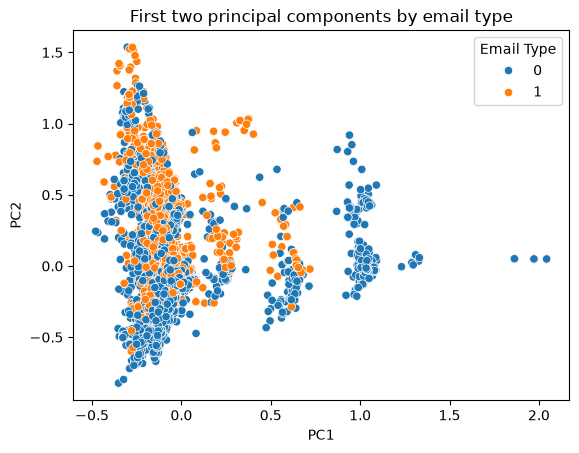

In [20]:
import seaborn as sns

sns.scatterplot(x=PC1, y=PC2, hue=df_phishing['Email Type'])
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('First two principal components by email type')
plt.show()

In [16]:
pca_emails_multiple = PCA(n_components=2610).fit(X_train)
X_train_pca = pca_emails_multiple.transform(X_train)

X_test_pca = pca_emails_multiple.transform(X_test)

pca_lr_model = LinearRegression().fit(X_train_pca, y_train)

print('R-sqaured -- training set:', round(pca_lr_model.score(X_train_pca, y_train), 4))
print('R-sqaured -- test set:', round(pca_lr_model.score(X_test_pca, y_test), 4))

# Performance is nearly identical to the regression on the original features, with a very slightly higher test R-squared. Keeping 2,610 of 2,711 components retains almost all the information, so this is essentially thesame model. Dropping ~100 low-variance components changes little.

: 

In [ ]:
# PCA turns thousands of correlated word columns into a smaller set of uncorrelated components ordered by how much variance they capture. This removes multicollinearity, which makes regression coefficients unstable, and lets us use far fewer predictors by keeping only the top components. 
# Fewer predictors means less noise to overfit, lower variance, and faster computation, while still preserving most of the variation in the data. 
# The tradeoff is that components are combinations of words, so they are harder to interpret than individual word coefficients

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

AI was helpful in catching errors that I missed while scanning over code, for isntance when I forgot to change my R-sqaured value when I changed my code. AI also is good at assisting your code to make it more simple and removing unnecesassary variables and code blocks. A limitation is that it does not have access to the data sets we were pulling from. Especailly because they were too large for my computer to run well, I ran into a lot of kernel crashes that prevented code from running. AI was not able to forsee this. However, to its advantage, it was able to work through code blocks as if there was no issue